# Predicción del precio de un jugador


## 1. Librerias y funciones

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.ticker as mticker
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFECV
#Configure Defaults
import warnings
import os
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 500)
plt.rcParams["figure.figsize"] = 10,5

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def q01(x): return x.quantile(0.01)
def q05(x): return x.quantile(0.05)
def q25(x): return x.quantile(0.25)
def q50(x): return x.quantile(0.50)
def q75(x): return x.quantile(0.75)
def q80(x): return x.quantile(0.80)
def q90(x): return x.quantile(0.90)
def q95(x): return x.quantile(0.95)
def q99(x): return x.quantile(0.99)
def desv(x): return np.std(x)


def Columnas_con_missing(df):
    mis_val = df.isnull().sum()
    mis_val_percent = 100 * df.isnull().sum() / len(df)
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
    mis_val_table_ren_columns = mis_val_table.rename(
    columns = {0 : 'Missing Values', 1 : '% of Total Values'})
    mis_val_table_ren_columns = mis_val_table_ren_columns[mis_val_table_ren_columns.iloc[:,1] != 0].sort_values('% of Total Values', ascending=False).round(1)
    print ("La tabla seleccionada con " + str(df.shape[1]) + " columnas.\n" "Tiene " + str(mis_val_table_ren_columns.shape[0]) +" columnas con valores nulos.")
    return mis_val_percent.sort_values(ascending=False).head(mis_val_table_ren_columns.shape[0])

def correlation_heatmap(df, method):
    #_ , ax = plt.subplots(figsize =(7,4))
    colormap = sns.diverging_palette(220, 10, as_cmap = True)

    _ = sns.heatmap(
        df.corr(method=method),
        cmap = colormap,
        square=True,
        annot=True,
        annot_kws={'fontsize':9 }
    )
    plt.title('Correlation Matrix', y=1.05, size=15)

## 2. Carga de datos

In [ ]:
data_fifa22 =  pd.read_csv('/content/drive/MyDrive/DATA_PRACTICA/players_22.csv',sep=',')

In [ ]:
data_fifa22.head(5)

,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,dob,height_cm,weight_kg,club_team_id,club_name,league_name,league_level,club_position,club_jersey_number,club_loaned_from,club_joined,club_contract_valid_until,nationality_id,nationality_name,nation_team_id,nation_position,nation_jersey_number,preferred_foot,weak_foot,skill_moves,international_reputation,work_rate,body_type,real_face,release_clause_eur,player_tags,player_traits,pace,shooting,passing,dribbling,defending,physic,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,1987-06-24,170,72,73.0,Paris Saint-Germain,French Ligue 1,1.0,RW,30.0,NaN,2021-08-10,2023.0,52,Argentina,1369.0,RW,10.0,Left,4,4,5,Medium/Low,Unique,Yes,144300000.0,"#Dribbler, #Distance Shooter, #FK Specialist, ...","Finesse Shot, Long Shot Taker (AI), Playmaker ...",85.0,92.0,91.0,95.0,34.0,65.0,85,95,70,91,88,96,93,94,91,96,91,80,91,94,95,86,68,72,69,94,44,40,93,95,75,96,20,35,24,6,11,15,14,8,NaN,89+3,89+3,89+3,92,93,93,93,92,93,93,93,91+2,87+3,87+3,87+3,91+2,66+3,64+3,64+3,64+3,66+3,61+3,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,1988-08-21,185,81,21.0,FC Bayern München,German 1. Bundesliga,1.0,ST,9.0,NaN,2014-07-01,2023.0,37,Poland,1353.0,RS,9.0,Right,4,4,5,High/Medium,Unique,Yes,197200000.0,"#Aerial Threat, #Distance Shooter, #Clinical F...","Solid Player, Finesse Shot, Outside Foot Shot,...",78.0,92.0,79.0,86.0,44.0,82.0,71,95,90,85,89,85,79,85,70,88,77,79,77,93,82,90,85,76,86,87,81,49,95,81,90,88,35,42,19,15,6,12,8,10,NaN,90+2,90+2,90+2,85,88,88,88,85,86+3,86+3,86+3,84+3,80+3,80+3,80+3,84+3,64+3,66+3,66+3,66+3,64+3,61+3,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,1985-02-05,187,83,11.0,Manchester United,English Premier League,1.0,ST,7.0,NaN,2021-08-27,2023.0,38,Portugal,1354.0,ST,7.0,Right,4,5,5,High/Low,Unique,Yes,83300000.0,"#Aerial Threat, #Dribbler, #Distance Shooter, ...","Power Free-Kick, Flair, Long Shot Taker (AI), ...",87.0,94.0,80.0,88.0,34.0,75.0,87,95,90,80,86,88,81,84,77,88,85,88,86,94,74,94,95,77,77,93,63,29,95,76,88,95,24,32,24,7,11,15,14,11,NaN,90+1,90+1,90+1,88,89,89,89,88,86+3,86+3,86+3,86+3,78+3,78+3,78+3,86+3,63+3,59+3,59+3,59+3,63+3,60+3,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png


In [ ]:
#dimensiones - cantidad ilas y columnas
data_fifa22.shape

(19239, 110)

In [ ]:
#Revisamos la información general de nuestros datos
data_fifa22.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Columns: 110 entries, sofifa_id to nation_flag_url
dtypes: float64(16), int64(44), object(50)
memory usage: 16.1+ MB


In [ ]:
#Buscamos las viarables con valores nulos.
#Columnas_con_missing(data_fifa22)

## Elimanación de Columnas

In [ ]:
#ELiminamos las columnas que contengan URL
data_fifa22 = data_fifa22[data_fifa22.columns.drop(list(data_fifa22.filter(regex = 'url')))]
data_fifa22.shape

(19239, 104)

In [ ]:
#Revisamos columnas que tengan muchos datos faltantes (>50%)
col_borrar = []

print("Columnas que tiene mas del 50% de datos faltantes: \n")

for i in data_fifa22.columns:
    missing = np.abs(( data_fifa22[i].count() -  data_fifa22[i].shape[0])/ data_fifa22[i].shape[0] * 100)
    if missing > 50:
        print('{} - {}%'.format(i, round(missing)))
        col_borrar.append(i)



Columnas que tiene mas del 50% de datos faltantes: 

club_loaned_from - 94%
nation_team_id - 96%
nation_position - 96%
nation_jersey_number - 96%
player_tags - 93%
player_traits - 51%
goalkeeping_speed - 89%


In [ ]:
data_fifa22.drop(columns = col_borrar, inplace = True)
print(data_fifa22.shape)

(19239, 97)


In [ ]:
data_fifa22.rename(columns={'skill_moves':'skills'},inplace=True)

In [ ]:
filter = ['sofifa_id','skill_','movement_','defending_','goalkeeping_','attacking_','power_','mentality_']

for i in filter:
   data_fifa22 = data_fifa22[data_fifa22.columns.drop(list(data_fifa22.filter(regex=i)))]

data_fifa22.shape

(19239, 62)

In [ ]:
data_fifa22.columns

Index(['short_name', 'long_name', 'player_positions', 'overall', 'potential',
       'value_eur', 'wage_eur', 'age', 'dob', 'height_cm', 'weight_kg',
       'club_team_id', 'club_name', 'league_name', 'league_level',
       'club_position', 'club_jersey_number', 'club_joined',
       'club_contract_valid_until', 'nationality_id', 'nationality_name',
       'preferred_foot', 'weak_foot', 'skills', 'international_reputation',
       'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'pace',
       'shooting', 'passing', 'dribbling', 'defending', 'physic', 'ls', 'st',
       'rs', 'lw', 'lf', 'cf', 'rf', 'rw', 'lam', 'cam', 'ram', 'lm', 'lcm',
       'cm', 'rcm', 'rm', 'lwb', 'ldm', 'cdm', 'rdm', 'rwb', 'lb', 'lcb', 'cb',
       'rcb', 'rb', 'gk'],
      dtype='object')

In [ ]:
data_fifa = data_fifa22[['short_name','age','dob','height_cm','weight_kg','nationality_name','club_name','overall','potential',
          'value_eur','wage_eur','preferred_foot','international_reputation', 'pace', 'shooting', 'passing', 'dribbling', 'defending','physic']]

In [ ]:
#Despúes de la limpieza nos quedamos solamente con 17 columnas
#Con las cuales trabajaremos para hacer la predición
data_fifa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   short_name                19239 non-null  object 
 1   age                       19239 non-null  int64  
 2   dob                       19239 non-null  object 
 3   height_cm                 19239 non-null  int64  
 4   weight_kg                 19239 non-null  int64  
 5   nationality_name          19239 non-null  object 
 6   club_name                 19178 non-null  object 
 7   overall                   19239 non-null  int64  
 8   potential                 19239 non-null  int64  
 9   value_eur                 19165 non-null  float64
 10  wage_eur                  19178 non-null  float64
 11  preferred_foot            19239 non-null  object 
 12  international_reputation  19239 non-null  int64  
 13  pace                      17107 non-null  float64
 14  shooti

In [ ]:
#Verificacmos la cantidad total valores nulos por cada columnas o variables.
data_fifa.isnull().sum()

short_name                     0
age                            0
dob                            0
height_cm                      0
weight_kg                      0
nationality_name               0
club_name                     61
overall                        0
potential                      0
value_eur                     74
wage_eur                      61
preferred_foot                 0
international_reputation       0
pace                        2132
shooting                    2132
passing                     2132
dribbling                   2132
defending                   2132
physic                      2132
dtype: int64

# Analisis Exploratorio de los datos.

### 2.1. Variable objetivo ('value_eur')

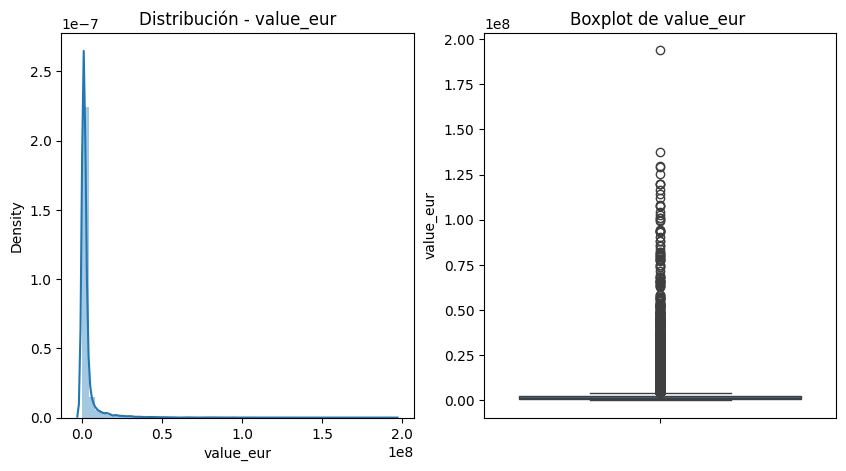

In [ ]:
#Análisis de la variable Objetivo
plt.subplot(1,2,1)
plt.title('Distribución - value_eur')
sns.distplot(data_fifa['value_eur'])

plt.subplot(1,2,2)
plt.title('Boxplot de value_eur ')
sns.boxplot(y=data_fifa['value_eur'])

plt.show()

El precio promedio de los jugadores es: 2850451.81 EUR


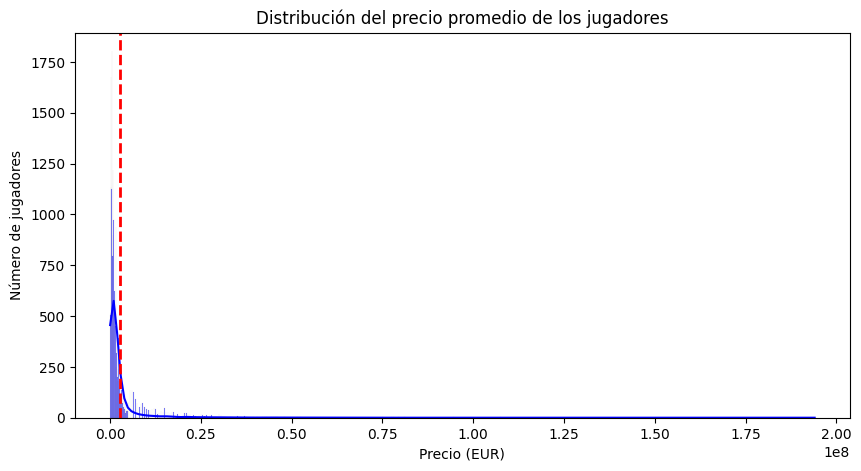

In [ ]:
# Calcular el precio promedio de los jugadores
avg_price = data_fifa['value_eur'].mean()

# Imprimir el precio promedio de los jugadores
print(f"El precio promedio de los jugadores es: {avg_price:.2f} EUR")

# Crear un histograma del precio de los jugadores
sns.histplot(data_fifa['value_eur'], kde=True, color='blue')
plt.axvline(x=avg_price, color='red', linestyle='dashed', linewidth=2)
plt.title('Distribución del precio promedio de los jugadores')
plt.xlabel('Precio (EUR)')
plt.ylabel('Número de jugadores')
plt.show()

* La distribución de los precios de los jugadores se centra alrededor de un rango específico de valores en euros(entre 0 y 2 mil millones).


* La densidad de precios es mayor en ciertos intervalos, lo que indica una concentración de jugadores dentro de esas gamas de precios.

<Figure size 1000x800 with 0 Axes>

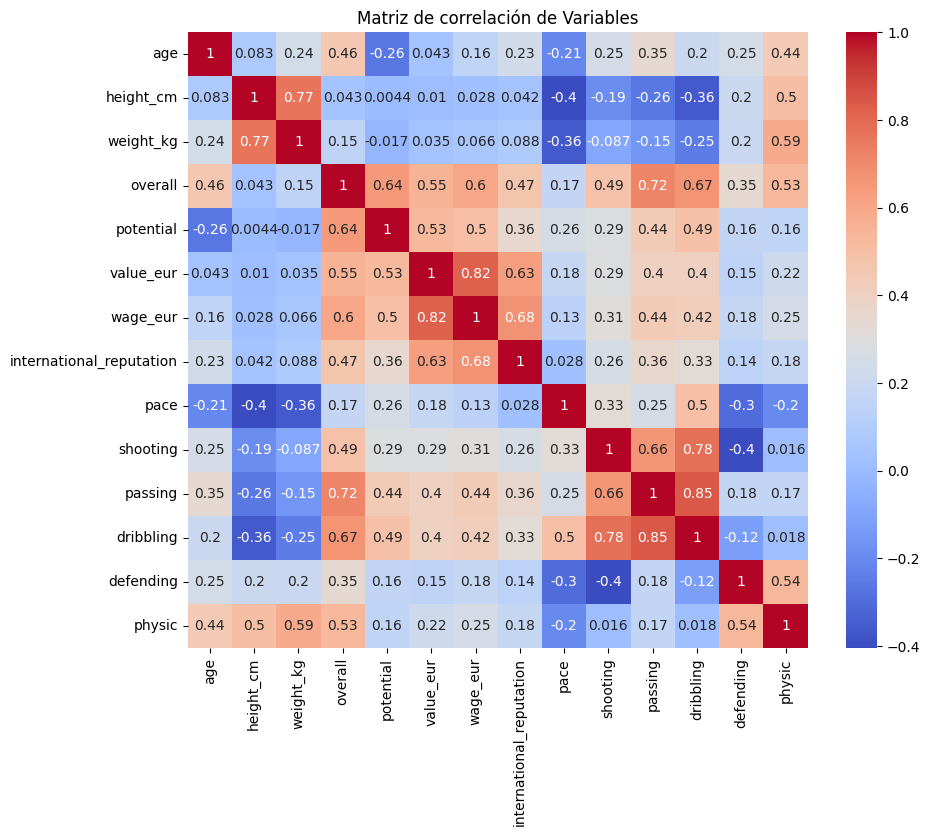

In [ ]:

# Matriz de correlación para evaluar la relación entre variables
plt.figure(figsize=(10, 8))
corr_matrix = data_fifa.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación de Variables')
plt.show()




*   El potencial tiene una correlación positiva con el valor y el salario.
*   La altura y el peso tienen una correlación positiva fuerte.

*   La altura y el peso tienen una correlación positiva fuerte.
*   La habilidad de driblar tiene una correlación positiva con el pase y la velocidad.

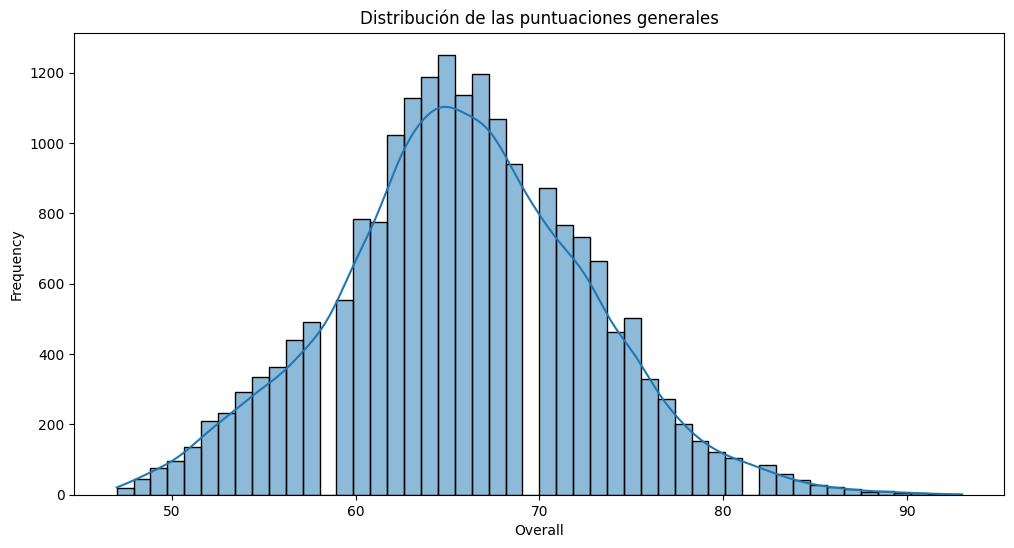

In [ ]:
#  Distribución general de las puntuaciones generales
# Distribución Normal
plt.figure(figsize=(12, 6))
sns.histplot(data_fifa, x='overall', kde=True, bins=50)
plt.title('Distribución de las puntuaciones generales')
plt.xlabel('Overall')
plt.ylabel('Frequency')
plt.show()



1.   La frecuencia más alta de puntuaciones se encuentra alrededor de 80 en la escala de puntuación general
2.   La distribución de las puntuaciones generales se centra principalmente en el rango de 60 a 90.



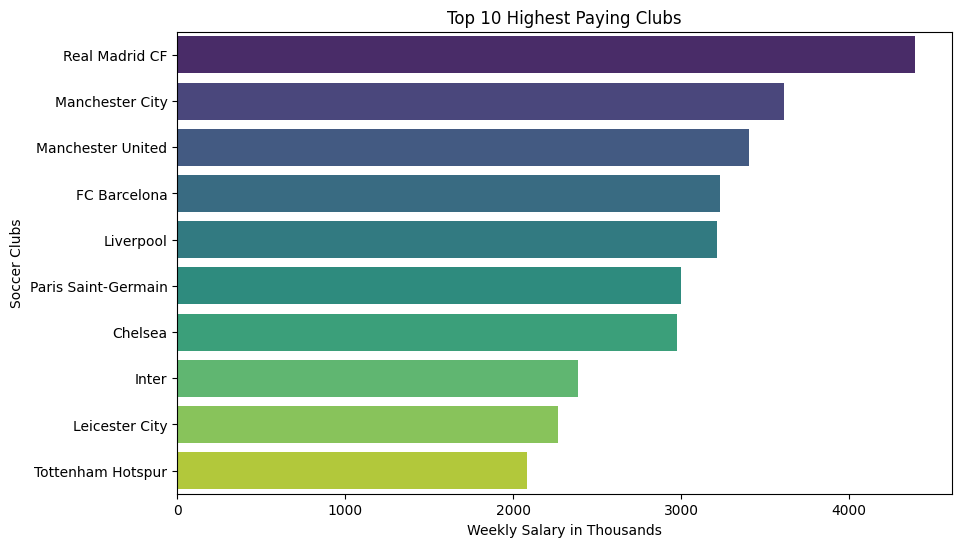

In [ ]:
# Nombres de ligas que mas pagan

# Agrupar por 'club_name' y sumar los salarios
def as_thousands(x):
    return round(x / 1000, 2)
top_clubs = data_fifa.groupby('club_name')['wage_eur'].sum().nlargest(10)

# Convertir los salarios a miles
top_clubs = top_clubs.apply(as_thousands)

# Crear el gráfico de barras horizontal
plt.figure(figsize=(10, 6))
sns.barplot(x=top_clubs, y=top_clubs.index, palette='viridis')
plt.xlabel('Weekly Salary in Thousands')
plt.ylabel('Soccer Clubs')
plt.title('Top 10 Highest Paying Clubs')
plt.show()




*  Real Madrid CF es el club que paga el salario más alto semanalmente entre los 10 clubes mencionados
*   Existe una brecha significativa entre el salario de Real Madrid CF y los demás clubes, lo que sugiere una diferencia considerable en la estructura salarial.

*  La competitividad en el fútbol moderno ha llevado a una escalada en los salarios de los jugadores, lo que se refleja en la lista de los clubes con los salarios más altos.





# **ANÁLISIS DEL PRECIO Y OTRAS VARIABLES**
wage_ur

In [ ]:
data_fifa['wage_eur'].describe()

count     19178.000000
mean       9017.989363
std       19470.176724
min         500.000000
25%        1000.000000
50%        3000.000000
75%        8000.000000
max      350000.000000
Name: wage_eur, dtype: float64

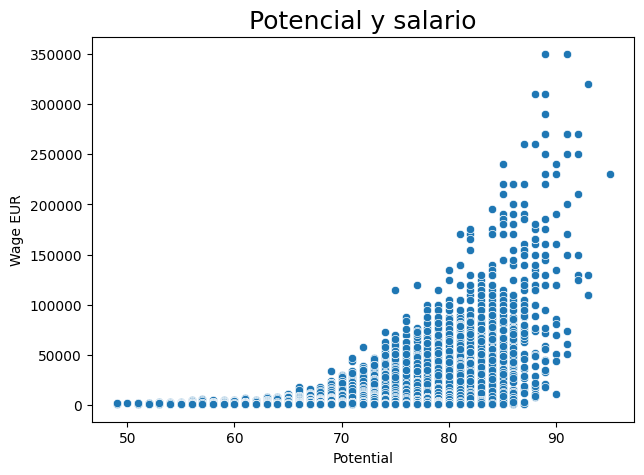

In [ ]:
# Relación entre el potencial del jugador y los salarios

plt.figure(figsize=(7, 5))
ax = sns.scatterplot(x =data_fifa['potential'], y = data_fifa['wage_eur'])
plt.xlabel("Potential")
plt.ylabel("Wage EUR")
plt.title("Potencial y salario", fontsize = 18)
plt.show()

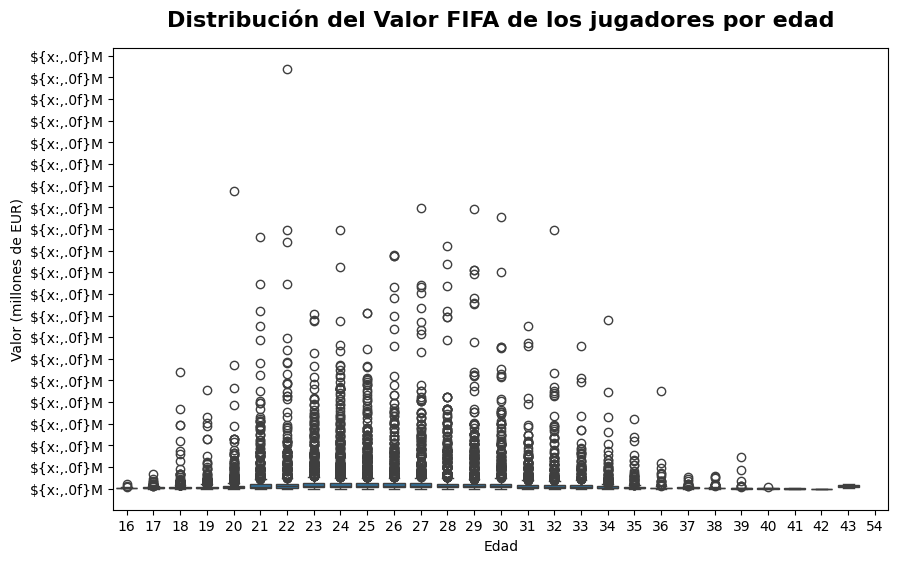

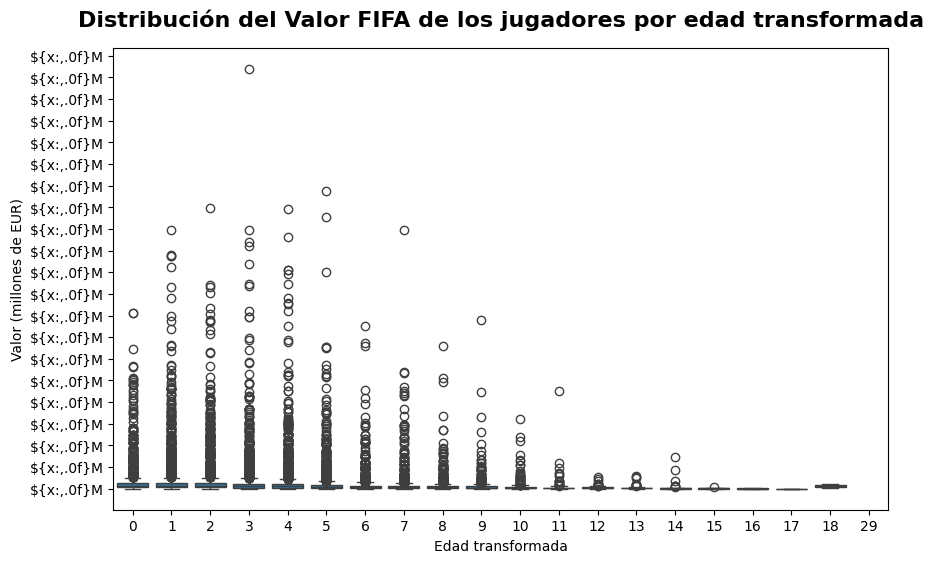

In [ ]:


# Convertir la columna 'value_eur' a miles
data_fifa['value_eur'] = data_fifa['value_eur'] / 1000000

# Crear el primer gráfico de cajas para la edad
fig, ax = plt.subplots(figsize=(10, 6))

# Formatear el eje y para mostrar valores en miles
fmt = '${x:,.0f}M'
tick_values = np.arange(0, 201, 10)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
ax.set_yticks(tick_values)

# Crear el gráfico de cajas
sns.boxplot(x='age', y='value_eur', data=data_fifa, ax=ax)

# Establecer los títulos de los ejes
ax.set_xlabel('Edad')
ax.set_ylabel('Valor (millones de EUR)')
ax.set_title('Distribución del Valor FIFA de los jugadores por edad', fontsize=16, fontweight='bold', pad=15)

# Mostrar el gráfico
plt.show()

# Crear una columna transformada en la tabla de datos
data_fifa['age_transformed'] = np.abs(data_fifa['age'] - 25)

# Crear el segundo gráfico de cajas para la edad transformada
fig, ax2 = plt.subplots(figsize=(10, 6))

# Formatear el eje y para mostrar valores en miles
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
ax2.set_yticks(tick_values)

# Crear el gráfico de cajas
sns.boxplot(x=data_fifa['age_transformed'], y=data_fifa['value_eur'], ax=ax2)

# Establecer los títulos de los ejes
ax2.set_xlabel('Edad transformada')
ax2.set_ylabel('Valor (millones de EUR)')
ax2.set_title('Distribución del Valor FIFA de los jugadores por edad transformada', fontsize=16, fontweight='bold', pad=15)

# Mostrar el gráfico
plt.show()


1. **Se observa una tendencia general de que el valor de los jugadores aumenta a medida que aumenta la edad hasta cierto punto.**


2. **A partir de los 25 años, se puede ver una variabilidad en los valores de los jugadores, con algunos picos y valles en la distribución.**

3. **Los jugadores más jóvenes tienden a tener valores más bajos en comparación con los jugadores de mayor edad.**

4. **Existe una concentración de valores de jugadores en ciertos grupos de edad, lo que puede indicar una tendencia en la valoración de los jugadores en función de su edad.**

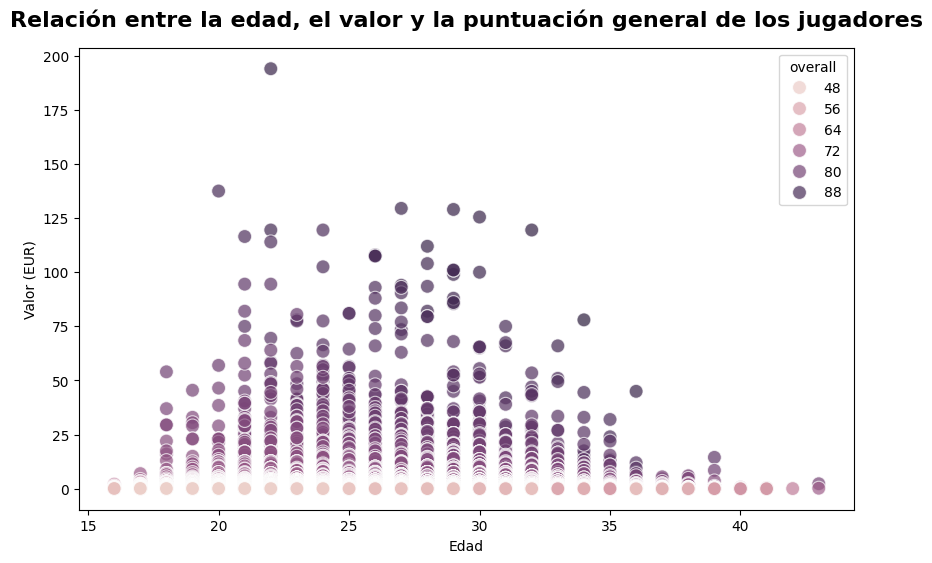

In [ ]:
# Crea una figura y un eje
fig, ax = plt.subplots(figsize=(10, 6))

# Crea el gráfico de dispersión
sns.scatterplot(x=data_fifa['age'], y=data_fifa['value_eur'], hue=data_fifa['overall'], s=100, alpha=0.7, ax=ax)

# Establece los títulos de los ejes
ax.set_xlabel('Edad')
ax.set_ylabel('Valor (EUR)')
ax.set_title('Relación entre la edad, el valor y la puntuación general de los jugadores', fontsize=16, fontweight='bold', pad=15)

# Personaliza la escala de color
colors = sns.color_palette('husl', 10)
for i, patch in enumerate(ax.get_legend().get_patches()):
    patch.set_facecolor(colors[i])

# Personaliza los valores del eje x
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

# Muestra el gráfico
plt.show()

*  **Los gráficos muestran que los jugadores más jóvenes tienden a tener valores más altos que los jugadores de mayor edad con las mismas puntuaciones generales**

*  **Además, los jugadores con puntuaciones más altas tienden a tener valores más altos que los jugadores con puntuaciones más bajas, independientemente de su edad.**

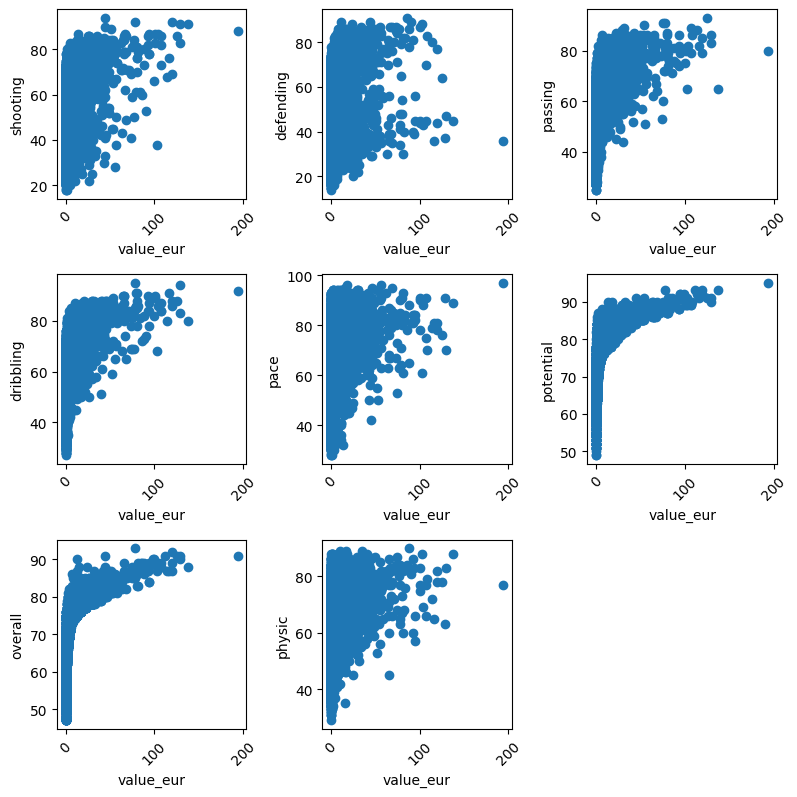

In [ ]:
# Comparación de la relación de cada variable con value_Eur
data_ff = data_fifa[['shooting','defending','passing','dribbling','pace','potential','overall', 'physic']]

plt.figure(figsize=(9, 9))

plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.4,
                    hspace=0.4)

width = 3
height = 3
index = 1
for i in data_ff.columns:
    plt.subplot(height, width, index)
    plt.scatter(x=data_fifa['value_eur'],y=data_ff[i])
    plt.xlabel('value_eur')
    plt.ylabel(i)
    plt.xticks(rotation=45)
    index = index + 1

* **Se observa que el valor en euros de los jugadores aumenta a medida que aumenta su habilidad en ciertas áreas como overall, potential, shooting, dribbling, pace, passing, defending y physic.**

1. **Las habilidades como overall y potential parecen tener una correlación positiva más fuerte con el valor en euros en comparación con otras habilidades.**
2. **La habilidad de shooting también muestra una correlación positiva significativa con el valor de los jugadores.**

3. **Las habilidades como defending y physic parecen tener una correlación menos pronunciada con el valor en euros.**

In [ ]:
# Overall score of the players
data_fifa.sort_values(by='overall',ascending=False)[["short_name","overall","age"]].head(20)

,short_name,overall,age
0,L. Messi,93,34
1,R. Lewandowski,92,32
2,Cristiano Ronaldo,91,36
3,Neymar Jr,91,29
4,K. De Bruyne,91,30
5,J. Oblak,91,28
6,K. Mbappé,91,22
7,M. Neuer,90,35
8,M. ter Stegen,90,29
9,H. Kane,90,27


In [ ]:
top_players = data_fifa.sort_values(by='overall',ascending=False).head(20)
top_players.shape


(20, 20)

In [ ]:
top_players.head()

,short_name,age,dob,height_cm,weight_kg,nationality_name,club_name,overall,potential,value_eur,wage_eur,preferred_foot,international_reputation,pace,shooting,passing,dribbling,defending,physic,age_transformed
0,L. Messi,34,1987-06-24,170,72,Argentina,Paris Saint-Germain,93,93,78.0,320000.0,Left,5,85.0,92.0,91.0,95.0,34.0,65.0,9
1,R. Lewandowski,32,1988-08-21,185,81,Poland,FC Bayern München,92,92,119.5,270000.0,Right,5,78.0,92.0,79.0,86.0,44.0,82.0,7
2,Cristiano Ronaldo,36,1985-02-05,187,83,Portugal,Manchester United,91,91,45.0,270000.0,Right,5,87.0,94.0,80.0,88.0,34.0,75.0,11
3,Neymar Jr,29,1992-02-05,175,68,Brazil,Paris Saint-Germain,91,91,129.0,270000.0,Right,5,91.0,83.0,86.0,94.0,37.0,63.0,4
4,K. De Bruyne,30,1991-06-28,181,70,Belgium,Manchester City,91,91,125.5,350000.0,Right,4,76.0,86.0,93.0,88.0,64.0,78.0,5


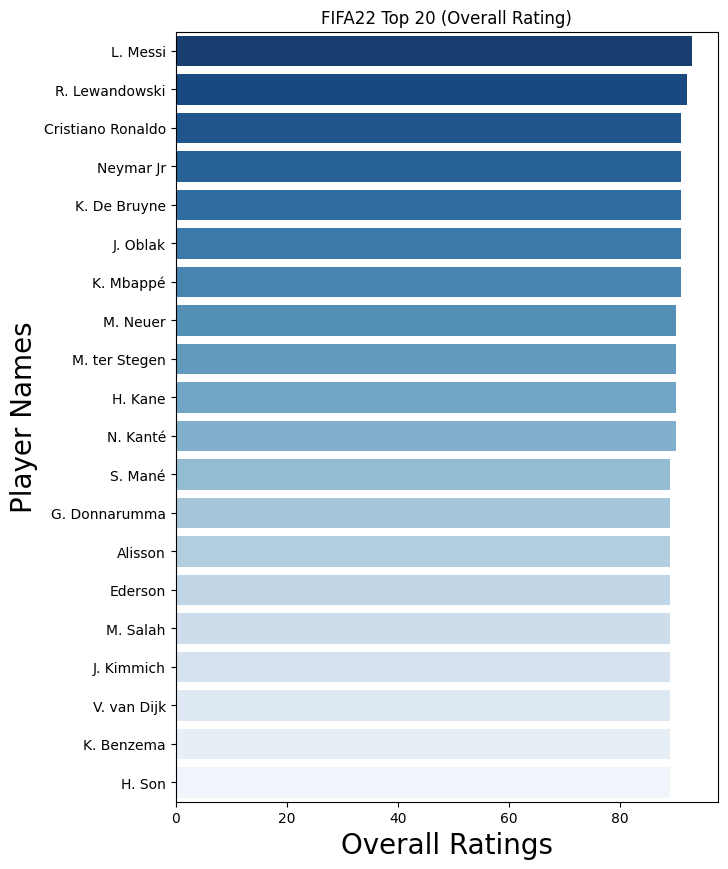

In [ ]:

# 20 mejores jugadores según su 'overall'
top_players = data_fifa.sort_values(by='overall',ascending=False).head(20)

# Extraemos los nombres de los jugadores y sus calificaciones en 'overall'
footballer_name = top_players['short_name']
Overall = top_players['overall']

# Creamos un nuevo dataframe con las columnas 'short_name' y 'overall'
data = pd.DataFrame({'short_name': footballer_name,'overall':Overall})

# Realizamos el gráfico de barras horizontales
plt.figure(figsize=(7,10))

ax= sns.barplot(x=Overall, y=footballer_name, palette = 'Blues_r', orient='h')
plt.xticks()
plt.xlabel('Overall Ratings', size = 20)
plt.ylabel('Player Names', size = 20 )
plt.title('FIFA22 Top 20 (Overall Rating)')

plt.show()

In [ ]:
data_fifa['international_reputation']


0        5
1        5
2        5
3        5
4        4
        ..
19234    1
19235    1
19236    1
19237    1
19238    1
Name: international_reputation, Length: 19239, dtype: int64

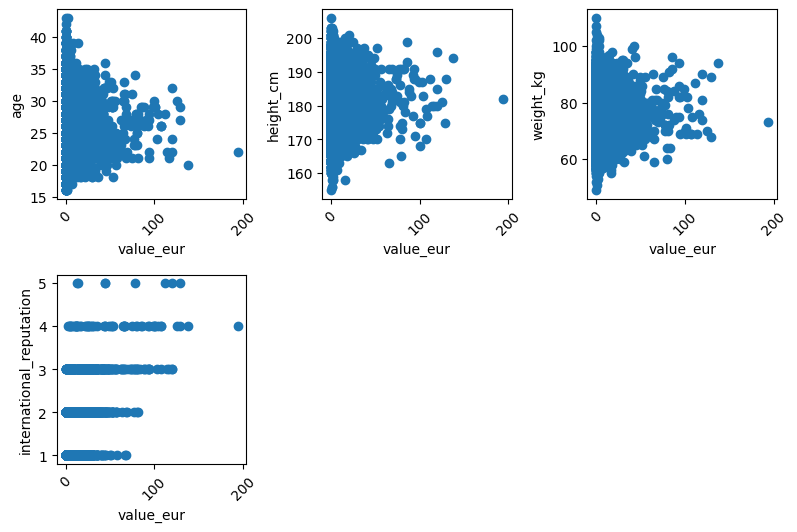

In [ ]:
# Comparación de la relación de cada variable con value_Eur
data_ff = data_fifa[['age','height_cm','weight_kg', 'international_reputation']]

plt.figure(figsize=(9, 9))

plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.4,
                    hspace=0.4)

width = 3
height = 3
index = 1
for i in data_ff.columns:
    plt.subplot(height, width, index)
    plt.scatter(x=data_fifa['value_eur'],y=data_ff[i])
    plt.xlabel('value_eur')
    plt.ylabel(i)
    plt.xticks(rotation=45)
    index = index + 1

* **Se observa que el valor en euros de los jugadores varía en función de su edad, altura, peso y reputación internacional.**

* **La edad y la altura parecen tener una influencia en el valor de los jugadores, donde ciertas edades y alturas pueden estar asociadas con valores más altos.**

* **El peso y la reputación internacional también parecen ser factores que influyen en el valor de los jugadores, con ciertos pesos y niveles de reputación que pueden correlacionarse con valores más altos.**

# Análisis de las variables mas importantes.

**Las variables mas importantes son:**
1.  overall, potential, shooting, dribbling, pace, passing, defending y physic.
2.  'age','height_cm','weight_kg', 'international_reputation'

In [ ]:
#puntuaciones promedio de los atributos mas importantes para los 20 mejores jugadores
print("Top 20 jugadores")
x = ['overall','potential','shooting','wage_eur','pace', 'passing','defending','physic']
for i in x:
    print("Mean {} :  {}".format(i,top_players[i].mean()))

Top 20 jugadores
Mean overall :  90.05
Mean potential :  90.85
Mean shooting :  83.42857142857143
Mean wage_eur :  232300.0
Mean pace :  82.5
Mean passing :  82.0
Mean defending :  52.0
Mean physic :  76.21428571428571


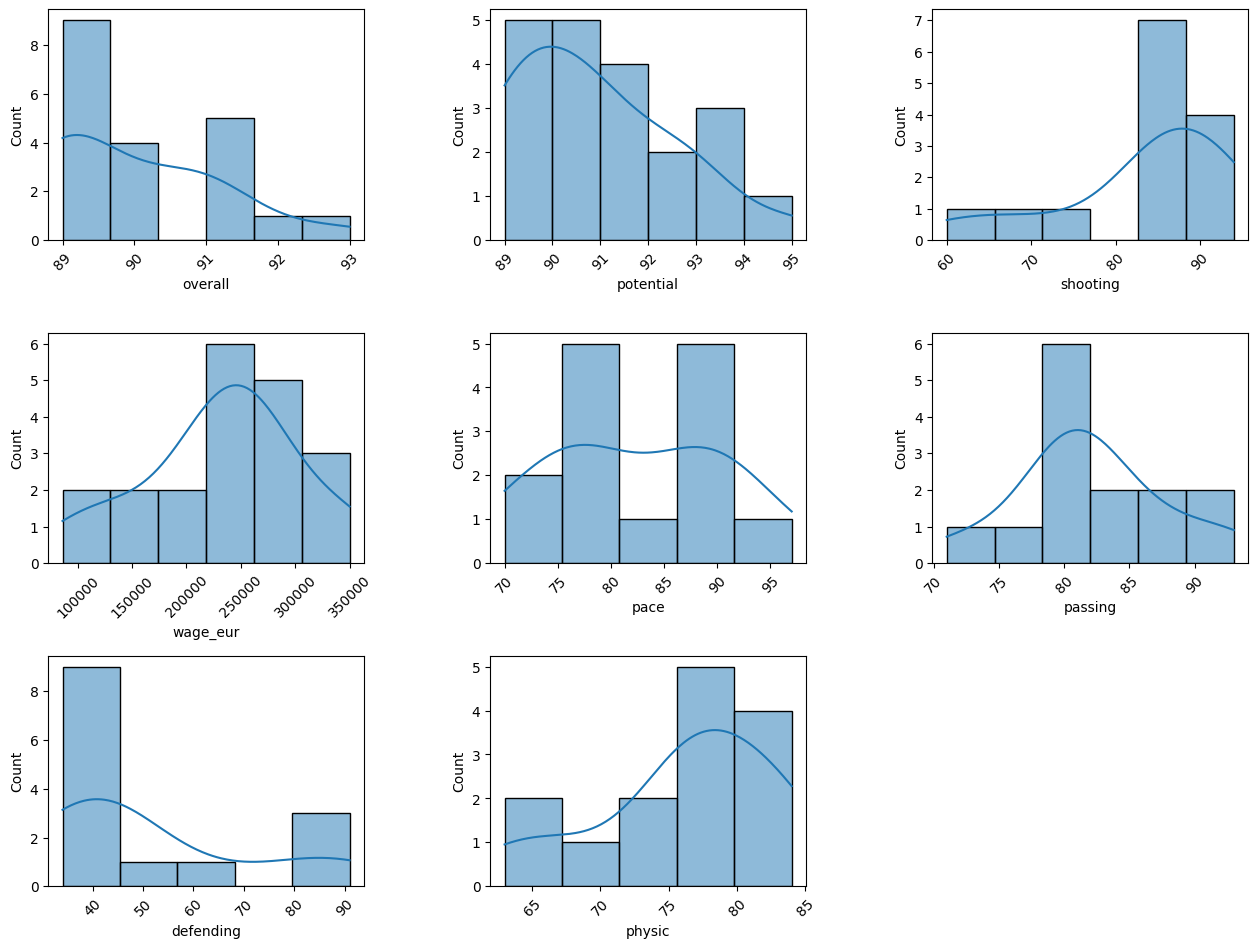

In [ ]:
plt.figure(figsize=(15,15))
x = ['overall','potential','shooting','wage_eur','pace', 'passing','defending','physic']
plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.4,
                    hspace=0.4)

width = 3
height = 4
index = 1
for i in x:
    plt.subplot(height, width, index)
    sns.histplot(x=top_players[i], kde=True)
    plt.xlabel(i)
    plt.xticks(rotation=45)
    index = index + 1

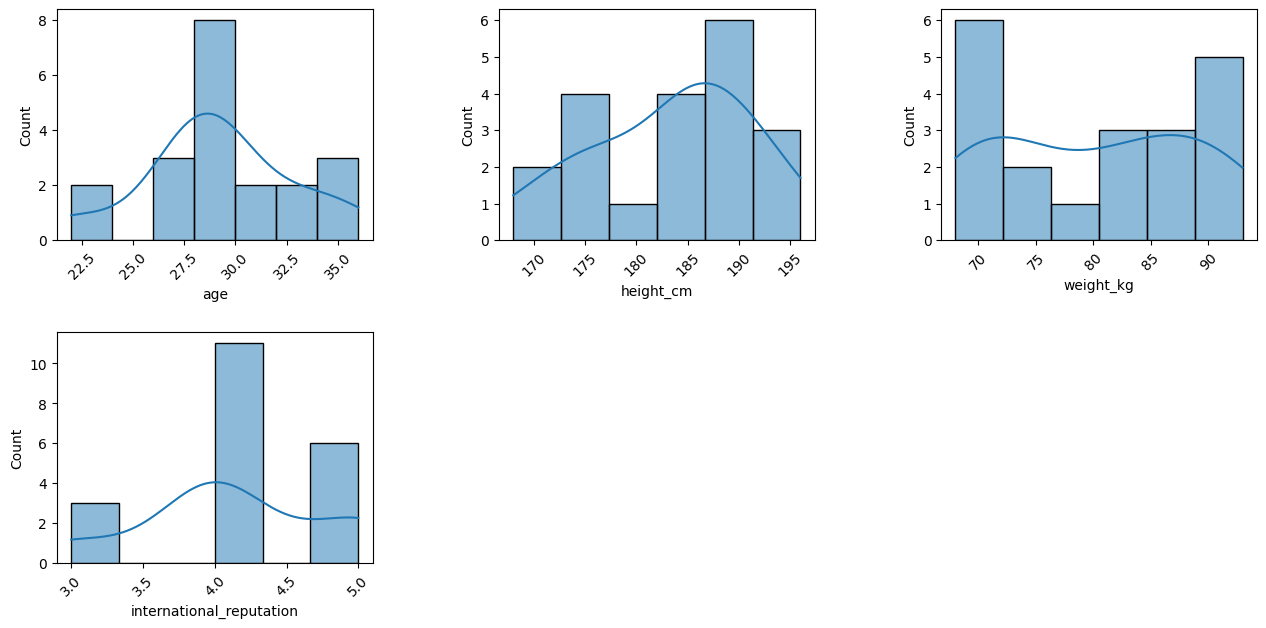

In [ ]:
plt.figure(figsize=(15,15))
x = ['age','height_cm','weight_kg', 'international_reputation']
plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.4,
                    hspace=0.4)

width = 3
height = 4
index = 1
for i in x:
    plt.subplot(height, width, index)
    sns.histplot(x=top_players[i], kde=True)
    plt.xlabel(i)
    plt.xticks(rotation=45)
    index = index + 1

In [ ]:
#Creando dataframe solo con las columnas mas importantes

dataf=data_fifa[['overall','potential','shooting','pace','passing','defending','physic','age','height_cm','weight_kg', 'international_reputation','wage_eur']]

dataf.head()

,overall,potential,shooting,pace,passing,defending,physic,age,height_cm,weight_kg,international_reputation,wage_eur
0,93,93,92.0,85.0,91.0,34.0,65.0,34,170,72,5,320000.0
1,92,92,92.0,78.0,79.0,44.0,82.0,32,185,81,5,270000.0
2,91,91,94.0,87.0,80.0,34.0,75.0,36,187,83,5,270000.0
3,91,91,83.0,91.0,86.0,37.0,63.0,29,175,68,5,270000.0
4,91,91,86.0,76.0,93.0,64.0,78.0,30,181,70,4,350000.0


In [ ]:
dataf.shape

(19239, 12)

In [ ]:

# Identificar variables con valores faltantes
variables_vacias = dataf.columns[dataf.isna().any()].tolist()
print("Variables con valores faltantes:", variables_vacias)

# Imputar valores faltantes utilizando la media
imputer = SimpleImputer(strategy='mean')
data_imputed = imputer.fit_transform(dataf)

# Convertir los datos imputados de nuevo en un DataFrame
data_imputed = pd.DataFrame(data_imputed, columns=dataf.columns)

# Verificar que ya no haya valores faltantes
print("Valores faltantes después de la imputación:", data_imputed.isnull().sum())


Variables con valores faltantes: ['shooting', 'pace', 'passing', 'defending', 'physic', 'wage_eur']
Valores faltantes después de la imputación: overall                     0
potential                   0
shooting                    0
pace                        0
passing                     0
defending                   0
physic                      0
age                         0
height_cm                   0
weight_kg                   0
international_reputation    0
wage_eur                    0
dtype: int64


In [ ]:
data_imputed.shape

(19239, 12)

In [ ]:
# Calcular la correlación entre las variables "overall" y "potencial"
correlation = data_imputed['overall'].corr(data_imputed['potential'])

# Mostrar el valor de la correlación
print("Correlación entre 'overall' y 'potencial':", correlation)


Correlación entre 'overall' y 'potencial': 0.6442751118832342


In [ ]:


# Seleccionar las características (variables independientes) y el objetivo (variable dependiente)
X = data_imputed[['overall','potential','shooting','pace','passing','defending','physic','age','height_cm','weight_kg', 'international_reputation']]  # Características del jugador
y = data_imputed['wage_eur']  # Valor del jugador en euros

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializar el estimador de regresión lineal
estimator = LinearRegression()

# Inicializar RFECV con el estimador y el esquema de validación cruzada
rfecv = RFECV(estimator=estimator, cv=5)

# Ajustar RFECV al conjunto de entrenamiento
rfecv.fit(X_train, y_train)

# Visualizar los resultados
print("Número óptimo de características:", rfecv.n_features_)
print("Ranking de características:", rfecv.ranking_)

# Crear un DataFrame con las variables y su ranking de características
ranking_df = pd.DataFrame({'Variable': X.columns, 'Ranking': rfecv.ranking_})

# Ordenar el DataFrame por el ranking
ranking_df = ranking_df.sort_values(by='Ranking')

# Mostrar el DataFrame
ranking_df.head(11)


Número óptimo de características: 11
Ranking de características: [1 1 1 1 1 1 1 1 1 1 1]


,Variable,Ranking
0,overall,1
1,potential,1
2,shooting,1
3,pace,1
4,passing,1
5,defending,1
6,physic,1
7,age,1
8,height_cm,1
9,weight_kg,1


In [ ]:
# Seleccionar las características (variables independientes) y el objetivo (variable dependiente)
X = data_imputed[['overall','potential','shooting','pace','passing','defending','physic','age','height_cm','weight_kg', 'international_reputation']]  # Características del jugador
y = data_imputed['wage_eur']  # Valor del jugador en euros

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializar y entrenar el modelo de regresión lineal
model = LinearRegression()
model.fit(X_train, y_train)

# Realizar predicciones sobre los datos de prueba
y_pred = model.predict(X_test)

# PREDICCION Y EVALUACIÓN DEL MODELO

In [ ]:
# Evaluar el rendimiento del modelo
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Error cuadrático medio (MSE):", mse)
print("Coeficiente de determinación (R^2):", r2)

#Ejemplo de predicción para un nuevo jugador
#new_player = np.array([[85, 25, 75, 80, 85]])  # Características del nuevo jugador
#predicted_value = model.predict(new_player)
#print("Valor predicho para el nuevo jugador:", predicted_value)

Error cuadrático medio (MSE): 149700747.51793158
Coeficiente de determinación (R^2): 0.588905121738381


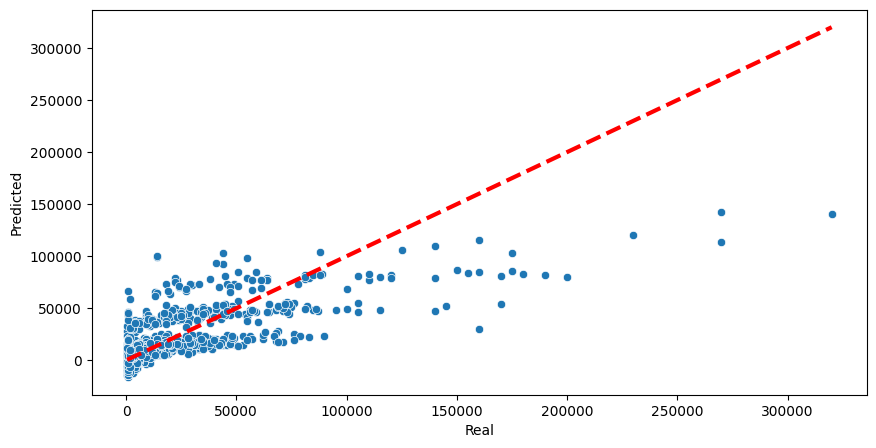

In [ ]:
#We plot the scatter for the linear regression model
data1 = pd.DataFrame({'Real': y_test, 'Predicted': y_pred})

sns.scatterplot(data=data1, x='Real', y='Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=3)
plt.xlabel('Real')
plt.ylabel('Predicted')
plt.show()